# College Earnings and Student Debt Analysis

## 1. Defining the Problem

This project examines which college type offers the strongest long-term earnings relative to student debt.

The analysis compares bachelor’s-degree institutions across three groups:

- Public
- Private nonprofit
- Private for-profit

The comparison focuses on median student debt at graduation, median earnings 10 years later, and the debt-to-earnings ratio.

## 2. Data Collection

The dataset comes from Kaggle ("US College Tuition, Debt and Graduate Salaries" by Harshit Kumar) and contains institution-level information on U.S. colleges, including college type, degree level, student debt, and long-term earnings.

Source: https://www.kaggle.com/datasets/harshitsama/us-college-tuition-debt-and-graduate-salaries

Only variables relevant to the project question are used in the analysis.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("us_college_earnings.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (5127, 26)


,institution,city,state,region,control,level,predominant_degree,admission_rate,sat_average,undergrad_enrollment,...,completion_rate,median_debt_at_graduation,median_earnings_6yr,median_earnings_10yr,earnings_p25_10yr,earnings_p75_10yr,pct_earning_over_25k_10yr,debt_to_earnings,latitude,longitude
0,ABC Beauty Academy,Richardson,TX,Southwest,Private for-profit,Less than 2-year,Certificate,NaN,NaN,52.0,...,0.8594,NaN,19991.0,16263,11880.0,35488.0,NaN,NaN,32.931698,-96.685333
1,ASPIRA City College,Philadelphia,PA,Mid East,Private nonprofit,2-year,Associate,0.5,NaN,8.0,...,0.5000,NaN,21998.0,34857,15520.0,53410.0,0.376,NaN,40.017493,-75.135042
2,ATA Career Education,Spring Hill,FL,Southeast,Private for-profit,4-year,Certificate,NaN,NaN,201.0,...,0.6667,21030.0,29724.0,34577,18900.0,47451.0,NaN,0.608,28.452699,-82.595376
3,ATA College,El Cajon,CA,Far West,Private for-profit,2-year,Certificate,NaN,NaN,80.0,...,0.8947,5500.0,35311.0,35017,23713.0,61513.0,NaN,0.157,32.819023,-116.981781
4,ATA College,Tulsa,OK,Southwest,Private for-profit,2-year,Associate,NaN,NaN,193.0,...,0.3333,21308.0,37674.0,40823,19190.0,66403.0,NaN,0.522,36.097005,-95.853281


## 3. Data Cleaning

The dataset was filtered to bachelor’s-degree institutions and reduced to the variables needed for the analysis.

Rows missing debt-related measures were removed (65 institutions). The final dataset contains 1,727 institutions.

In [3]:
college_clean = (
    df[df["predominant_degree"] == "Bachelor's"]
    [
        [
            "institution",
            "control",
            "median_debt_at_graduation",
            "median_earnings_10yr",
            "debt_to_earnings"
        ]
    ]
    .dropna(
        subset=[
            "median_debt_at_graduation",
            "median_earnings_10yr",
            "debt_to_earnings"
        ]
    )
    .drop_duplicates()
    .copy()
)

print("Final dataset shape:", college_clean.shape)

college_clean["control"].value_counts()

Final dataset shape: (1727, 5)


control
Private nonprofit     1020
Public                 582
Private for-profit     125
Name: count, dtype: int64

## 4. Analyzing the Data

In [4]:
order = ["Public", "Private nonprofit", "Private for-profit"]

summary = (
    college_clean
    .groupby("control")
    .agg(
        institutions=("institution", "count"),
        median_debt=("median_debt_at_graduation", "median"),
        median_earnings_10yr=("median_earnings_10yr", "median"),
        median_debt_to_earnings=("debt_to_earnings", "median")
    )
    .reindex(order)
)

summary

,institutions,median_debt,median_earnings_10yr,median_debt_to_earnings
control,,,,
Public,582,21000.0,54664.5,0.383
Private nonprofit,1020,24994.0,54659.5,0.444
Private for-profit,125,26123.0,40092.0,0.539


In [5]:
public_ratio = summary.loc["Public", "median_debt_to_earnings"]
nonprofit_ratio = summary.loc["Private nonprofit", "median_debt_to_earnings"]
forprofit_ratio = summary.loc["Private for-profit", "median_debt_to_earnings"]

nonprofit_vs_public = (
    (nonprofit_ratio - public_ratio) / public_ratio
) * 100

forprofit_vs_public = (
    (forprofit_ratio - public_ratio) / public_ratio
) * 100

print(
    f"Private nonprofit debt-to-earnings ratio is "
    f"{nonprofit_vs_public:.1f}% higher than Public."
)

print(
    f"Private for-profit debt-to-earnings ratio is "
    f"{forprofit_vs_public:.1f}% higher than Public."
)

Private nonprofit debt-to-earnings ratio is 15.9% higher than Public.
Private for-profit debt-to-earnings ratio is 40.7% higher than Public.


In [6]:
quartiles = (
    college_clean
    .groupby("control")["debt_to_earnings"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
    .reindex(order)
)

quartiles.columns = ["25th Percentile", "Median", "75th Percentile"]

quartiles

,25th Percentile,Median,75th Percentile
control,,,
Public,0.31025,0.383,0.449
Private nonprofit,0.35200,0.444,0.516
Private for-profit,0.27400,0.539,0.802


Public colleges had the lowest median debt-to-earnings ratio.

Private nonprofit institutions had a ratio about 16% higher than public institutions, while private for-profit institutions were about 41% higher.

The quartiles also show greater variation among private for-profit institutions. Their middle 50% of debt-to-earnings ratios spans a much wider range than the public-college group.

Group sizes are uneven, particularly because the private for-profit category contains substantially fewer institutions than the other two groups.

## 5. Visualize the Results

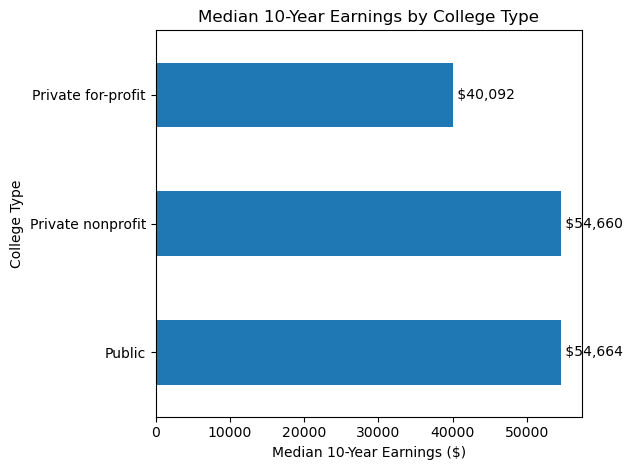

In [7]:
earnings = (
    college_clean
    .groupby("control")["median_earnings_10yr"]
    .median()
    .reindex(order)
)

ax = earnings.plot(kind="barh")

plt.title("Median 10-Year Earnings by College Type")
plt.xlabel("Median 10-Year Earnings ($)")
plt.ylabel("College Type")

for i, value in enumerate(earnings):
    ax.text(
        value,
        i,
        f" ${value:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

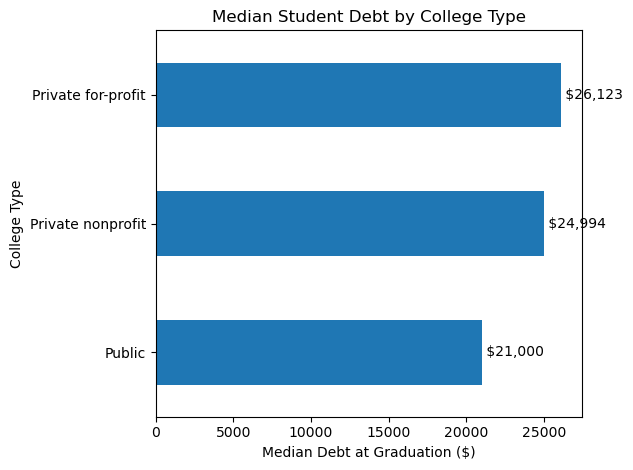

In [8]:
debt = (
    college_clean
    .groupby("control")["median_debt_at_graduation"]
    .median()
    .reindex(order)
)

ax = debt.plot(kind="barh")

plt.title("Median Student Debt by College Type")
plt.xlabel("Median Debt at Graduation ($)")
plt.ylabel("College Type")

for i, value in enumerate(debt):
    ax.text(
        value,
        i,
        f" ${value:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

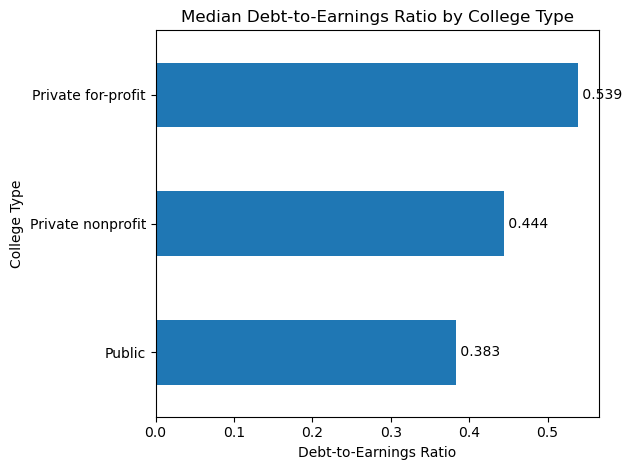

In [9]:
ratio = (
    college_clean
    .groupby("control")["debt_to_earnings"]
    .median()
    .reindex(order)
)

ax = ratio.plot(kind="barh")

plt.title("Median Debt-to-Earnings Ratio by College Type")
plt.xlabel("Debt-to-Earnings Ratio")
plt.ylabel("College Type")

for i, value in enumerate(ratio):
    ax.text(
        value,
        i,
        f" {value:.3f}",
        va="center"
    )

plt.tight_layout()
plt.show()

## 6. Interpret and Make Decisions

Among the bachelor’s-degree institutions analyzed, public colleges showed the strongest observed balance between long-term earnings and student debt. They had the lowest median debt ($21,000) and the lowest median debt-to-earnings ratio (0.38), with median 10-year earnings (about $54,660) nearly identical to private nonprofit institutions. Private for-profit institutions had the highest median debt ($26,123), the lowest median earnings ($40,092), and the highest ratio (0.54).

### Limitations

The results are descriptive and show associations, not causation.

College type alone does not determine future earnings. Outcomes may also be influenced by field of study, geographic location, student characteristics, labor-market conditions, and career choices.

The groups also differ substantially in sample size, with far fewer private for-profit institutions (125) than public (582) or private nonprofit (1,020) institutions.